# 03 – Finding 1: can earning more get you rejected?
**Test:** take every applicant, change **only** their monthly income, keep the other 7 fields the same,
and count how many are rejected at each income.
**Expected if the model is sensible:** more income → fewer rejections, always.

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
from common import BLUE, ORANGE, finish_chart, load_data, sweep, what_if

df = load_data()
incomes = [15000, 25000, 40000, 60000, 80000, 100000, 150000, 200000, 250000,
           300000, 350000, 400000, 600000, 1000000, 2000000]

## 1. All 600 applicants

In [2]:
everyone = sweep(df, "monthly_income", incomes, probe_file="03_income_sweep.csv")
everyone

,monthly_income,reject_rate,avg_risk
0,15000,0.802,0.801
1,25000,0.743,0.742
2,40000,0.642,0.643
3,60000,0.558,0.561
4,80000,0.517,0.518
5,100000,0.477,0.480
6,150000,0.437,0.433
7,200000,0.410,0.407
8,250000,0.383,0.387
9,300000,0.637,0.636


## 2. Only the applicants the model approves at ₹1.5 lakh/month

In [3]:
_, rejected = what_if(df, monthly_income=150000)
approved = df[~rejected]
good = sweep(approved, "monthly_income", incomes)
print(len(approved), "applicants approved at Rs1,50,000/month")
good

338 applicants approved at Rs1,50,000/month


,monthly_income,reject_rate,avg_risk
0,15000,0.651,0.650
1,25000,0.547,0.544
2,40000,0.367,0.369
3,60000,0.222,0.226
4,80000,0.151,0.154
5,100000,0.086,0.088
6,150000,0.000,0.006
7,200000,0.000,0.004
8,250000,0.003,0.007
9,300000,0.379,0.383


## 3. Chart

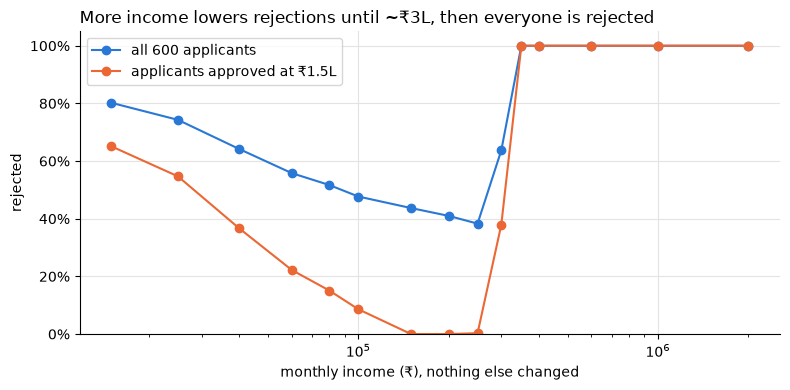

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(everyone.monthly_income, everyone.reject_rate, "o-", color=BLUE, label="all 600 applicants")
ax.plot(good.monthly_income, good.reject_rate, "o-", color=ORANGE, label="applicants approved at ₹1.5L")
ax.set_xscale("log")
ax.set_xlabel("monthly income (₹), nothing else changed")
ax.legend()
finish_chart(ax, "More income lowers rejections until ~₹3L, then everyone is rejected", "fig1_income.png")

## 4. Where exactly does each person flip to "reject"?
Raise income in ₹5,000 steps and record the first income where each approved person is rejected.

In [5]:
first_reject = {}
for income in range(150000, 400001, 5000):
    _, rejected = what_if(approved, monthly_income=income)
    for i in approved.index[rejected]:
        first_reject.setdefault(i, income)
flip = pd.Series(first_reject)
print(f"median Rs{flip.median():,.0f}, lowest Rs{flip.min():,}, highest Rs{flip.max():,}")

median Rs305,000, lowest Rs175,000, highest Rs350,000


**Conclusion:** risk falls with income as it should, up to about ₹2.5 lakh. Above about ₹3 lakh it
jumps, and from ₹3.5 lakh **every** applicant is rejected. This is the "well-off applicants rejected"
complaint.